<table style="width: 100%; margin-left: auto; margin-right: auto; background-color: white;">
<tbody>
<tr>

<td style="text-align: center; width: 12%;"><img src=img/brasil-brasao.png alt="" /></td>

<td style="width: 68%;">
<h2 style="text-align: center; margin-top: 1%;">Rep&uacute;blica Federativa do Brasil</h2>
<h2 style="text-align: center; margin-top: 1%;">Minist&eacute;rio da Educa&ccedil;&atilde;o</h2>
<h2 style="text-align: center; margin-top: 1%;">Universidade Federal do Amazonas</h2>
<h2 style="text-align: center; margin-top: 1%;">Instituto de Computa&ccedil;&atilde;o</h2>
</td>

<td style="width: 12%;"><img src="img/UFAM-logo.png" alt="" /></td>

</tr>
</tbody>
</table>

---

# Ciência de Dados

## Trabalho Prático I: Exploração de Dados, v 1.0

_Professor Dr. Marco Cristo_


**Alunos:** `Nome Sobrenome, Nome Sobrenome e Nome Sobrenome` <br>
**E-mail:** `nome.sobrenome@icomp.ufam.edu.br, nome.sobrenome@icomp.ufam.edu.br e nome.sobrenome@icomp.ufam.edu.br`


#### Sobre os dados

Este trabalho usa os microdados da Amostra do Censo Demográfico 2010 (IBGE), com foco no tema **Trabalho e Rendimento**. Cada equipe (este trabalho é para trios) trabalha sobre a população do seu **município** (especificado para a equipe) e a compara com o restante do país. Consulte o notebook `Dicionário de dados.ipynb` para a descrição de cada variável.

**Atenção**: por motivos didáticos, a base de dados contém alguns nulos e inconsistências propositalmente introduzidas (além dos nulos que já ocorrem naturalmente por questões de desenho da pesquisa do IBGE) — parte do seu trabalho na seção de Qualidade de Dados é justamente encontrá-los e tratá-los.


#### Preliminares


In [2]:
# Imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

import sklearn
import sys
import os

In [3]:
print("Python", sys.version)
print("--------")
print("Pandas:", pd.__version__)
print("Numpy:", np.__version__)
print("SKLearn:", sklearn.__version__)
pd.set_option('display.max_rows', None)

Python 3.13.5 (main, Aug 10 2026, 12:06:59) [GCC 14.2.0]
--------
Pandas: 3.0.3
Numpy: 2.2.6
SKLearn: 1.9.0


Escolha o arquivo de dados com o seu nome no diretório `data`.


In [4]:
DATA_PQT = 'data/censo2010_pessoas.parquet'
MUNICIPIO = 'São Bernardo do Campo' # Use o que foi especificado para sua equipe
SIGLA_UF = 'SP'      # Sigla da UF do município acima 

In [5]:
# Caminho do arquivo
df_censo = pd.read_parquet(DATA_PQT)
df_censo = df_censo[df_censo['SIGLA_UF']== 'SP']
df_censo = df_censo[df_censo['NOME_MUNICIPIO']== 'São Bernardo do Campo']
df_censo.info()



<class 'pandas.DataFrame'>
RangeIndex: 37593 entries, 3168586 to 3206178
Data columns (total 45 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   COD_UF                          37593 non-null  str    
 1   COD_MUNICIPIO_UF                37593 non-null  str    
 2   AREA_PONDERACAO                 37593 non-null  str    
 3   V0300                           37593 non-null  int64  
 4   PESO_AMOSTRAL                   37593 non-null  float64
 5   SEXO                            37593 non-null  str    
 6   IDADE                           37593 non-null  int64  
 7   COR_RACA                        36833 non-null  str    
 8   NIVEL_INSTRUCAO                 36887 non-null  str    
 9   COND_ATIVIDADE                  32735 non-null  str    
 10  COND_OCUPACAO                   20316 non-null  str    
 11  SITUACAO_OCUPACAO               32735 non-null  str    
 12  POSICAO_OCUPACAO                186

---

#### Qualidade de dados


<div class="alert alert-info">
    <b>(0,2) 1</b> - Quais colunas possuem campos nulos em <code>df_censo</code>? Ordene-as da que tem mais nulos para a que tem menos.
</div>


In [7]:
df_censo.isnull().sum().sort_values(ascending=False)[lambda x: x > 0]

SUBGRUPO_OCUPACAO                 22701
RENDA_BRUTA_TRAB_PRINCIPAL        19199
HORAS_TRABALHADAS_SEMANA          18976
COD_ATIVIDADE_ECON                18976
COD_OCUPACAO                      18976
POSICAO_OCUPACAO                  18976
RENDA_TODOS_TRABALHOS             18976
RENDA_TODOS_TRABALHOS_SM          18976
RENDA_TRAB_PRINCIPAL              18976
COND_OCUPACAO                     17277
TEM_INTERNET                      13141
COND_ATIVIDADE                     4858
SITUACAO_OCUPACAO                  4858
RENDA_TOTAL_SM                     4858
RENDA_TOTAL                        4858
COR_RACA                            760
RENDA_DOMICILIAR_PER_CAPITA         730
NIVEL_INSTRUCAO                     706
ESGOTAMENTO_SANITARIO               209
DESTINO_LIXO                        192
NUM_BANHEIROS                       192
AGUA_CANALIZADA                     192
TEM_TELEVISAO                       192
TEM_GELADEIRA                       192
TEM_COMPUTADOR                      192


As colunas do DataFrame df_censo que possuem campos nulos, ordenadas da maior quantidade para a menor, são: SUBGRUPO_OCUPACAO (22.701), RENDA_BRUTA_TRAB_PRINCIPAL (19.199), HORAS_TRABALHADAS_SEMANA, COD_ATIVIDADE_ECON, COD_OCUPACAO, POSICAO_OCUPACAO, RENDA_TODOS_TRABALHOS, RENDA_TODOS_TRABALHOS_SM e RENDA_TRAB_PRINCIPAL (18.976 cada), COND_OCUPACAO (17.277), TEM_INTERNET (13.141), COND_ATIVIDADE, SITUACAO_OCUPACAO, RENDA_TOTAL_SM e RENDA_TOTAL (4.858 cada), COR_RACA (760), RENDA_DOMICILIAR_PER_CAPITA (730), NIVEL_INSTRUCAO (706), ESGOTAMENTO_SANITARIO (209) e DESTINO_LIXO (192).


<div class="alert alert-primary">
<b>(0,1) 1.1</b> - Várias dessas colunas têm nulos pelo mesmo motivo: o questionário do Censo pula perguntas que não se aplicam a quem responde (ex.: perguntas sobre o trabalho não fazem sentido para quem não trabalha). Escolha três colunas com muitos nulos e explique, olhando o dicionário de dados, por que elas têm nulos "estruturais" (que não são erro, mas sim ausência de aplicabilidade da pergunta).
</div>


SUBGRUPO_OCUPACAO (22.701 nulos): essa variável identifica o subgrupo da ocupação profissional. Os valores podem estar ausentes porque a pergunta se aplica somente a pessoas com ocupação que possa ser classificada nessa categoria.
RENDA_BRUTA_TRAB_PRINCIPAL (19.199 nulos): essa variável registra a renda bruta recebida no trabalho principal. Para pessoas que não possuem trabalho principal, a pergunta não se aplica, o que pode explicar a ausência de informações.
HORAS_TRABALHADAS_SEMANA (18.976 nulos): essa variável registra a quantidade de horas trabalhadas por semana. Para pessoas que não exerceram trabalho no período de referência, essa informação pode não ser aplicável, resultando em valores nulos.


<div class="alert alert-info">
<b>(0,25) 2</b> - Investigue a relação entre <code>IDADE</code> e os nulos em <code>RENDA_TOTAL</code>. Existe um padrão claro? Baseado nisso, decida um critério de idade mínima para manter no conjunto de dados e remova as instâncias fora desse critério.
</div>

<i>Dica</i>: compare a distribuição de <code>IDADE</code> entre quem tem <code>RENDA_TOTAL</code> nulo e quem não tem.


In [10]:


renda_nula = df_censo[df_censo['RENDA_TOTAL'].isnull()]
renda_preenchida = df_censo[df_censo['RENDA_TOTAL'].notnull()]

# Comparar a distribuição das idades


# Verificar a proporção de nulos por idade
taxa_nulos = df_censo.groupby('IDADE')['RENDA_TOTAL'].apply(
    lambda x: x.isnull().mean() * 100
)

print("Percentual de RENDA_TOTAL nula por idade:")
print(taxa_nulos.to_string())

Percentual de RENDA_TOTAL nula por idade:
IDADE
0      100.0
1      100.0
2      100.0
3      100.0
4      100.0
5      100.0
6      100.0
7      100.0
8      100.0
9      100.0
10       0.0
11       0.0
12       0.0
13       0.0
14       0.0
15       0.0
16       0.0
17       0.0
18       0.0
19       0.0
20       0.0
21       0.0
22       0.0
23       0.0
24       0.0
25       0.0
26       0.0
27       0.0
28       0.0
29       0.0
30       0.0
31       0.0
32       0.0
33       0.0
34       0.0
35       0.0
36       0.0
37       0.0
38       0.0
39       0.0
40       0.0
41       0.0
42       0.0
43       0.0
44       0.0
45       0.0
46       0.0
47       0.0
48       0.0
49       0.0
50       0.0
51       0.0
52       0.0
53       0.0
54       0.0
55       0.0
56       0.0
57       0.0
58       0.0
59       0.0
60       0.0
61       0.0
62       0.0
63       0.0
64       0.0
65       0.0
66       0.0
67       0.0
68       0.0
69       0.0
70       0.0
71       0.0
72       0.0
73 

In [ ]:

#A partir dos 10 anos seria válido como régua, pois abaixo disso há somente valores nulos
idade_minima = 10

# Quantidade de registros antes da filtragem
total_antes = len(df_censo)

# Remover registros com idade inferior a 10 anos
df_censo = df_censo[df_censo['IDADE'] >= idade_minima].copy()

# Quantidade de registros removidos
removidos = total_antes - len(df_censo)

# Log da operação
print("=== FILTRAGEM POR IDADE ===")
print(f"Idade mínima adotada: {idade_minima} anos")
print(f"Registros antes: {total_antes}")
print(f"Registros removidos: {removidos}")
print(f"Registros restantes: {len(df_censo)}")

=== FILTRAGEM POR IDADE ===
Idade mínima adotada: 10 anos
Registros antes: 37593
Registros removidos: 4849
Registros restantes: 32744


<div class="alert alert-primary">
<b>(0,15) 2.1</b> - Depois de aplicar o filtro acima, ainda restam nulos em <code>RENDA_TOTAL</code>? Se sim, quantos, e o que isso sugere?
</div>


In [12]:

nulos_restantes = df_censo['RENDA_TOTAL'].isnull().sum()

print("=== VERIFICAÇÃO DE NULOS ===")
print(f"Nulos restantes em RENDA_TOTAL: {nulos_restantes}")

if nulos_restantes > 0:
    print("Ainda existem valores nulos após o filtro.")
    print("Isso sugere que os nulos também podem estar relacionados")
    print("a outros fatores além da idade.")
else:
    print("Não restam valores nulos em RENDA_TOTAL.")

=== VERIFICAÇÃO DE NULOS ===
Nulos restantes em RENDA_TOTAL: 9
Ainda existem valores nulos após o filtro.
Isso sugere que os nulos também podem estar relacionados
a outros fatores além da idade.


Após aplicar o filtro de idade mínima de 10 anos, ainda restaram **9 valores nulos** na coluna `RENDA_TOTAL`. Isso sugere que a ausência de dados não está relacionada exclusivamente à idade, podendo também estar associada a outros fatores, como a situação ocupacional dos entrevistados ou a falta de informações sobre a renda. Portanto, o filtro reduziu os valores nulos, mas não eliminou completamente o problema.


<div class="alert alert-info">
<b>(0,3) 3</b> - Verifique se há valores de <code>IDADE</code> ou <code>SEXO</code> fora do domínio esperado pelo dicionário de dados (idades implausíveis, códigos de sexo diferentes de 1/2). Trate essas inconsistências.
</div>


In [13]:

# Verificar valores inconsistentes
print("=== VERIFICAÇÃO DE INCONSISTÊNCIAS ===")

# Verificar idades fora do intervalo plausível
idades_invalidas = df_censo[
    (df_censo['IDADE'] < 0) | (df_censo['IDADE'] > 120)
]

print(f"Registros com idade inválida: {len(idades_invalidas)}")

# Verificar códigos de sexo diferentes de 1 e 2
sexos_invalidos = df_censo[
    ~df_censo['SEXO'].astype(str).isin(['1', '2'])
]

print(f"Registros com sexo inválido: {len(sexos_invalidos)}")

# Remover registros inconsistentes
df_censo = df_censo[
    df_censo['IDADE'].between(0, 120) &
    df_censo['SEXO'].astype(str).isin(['1', '2'])
].copy()

print("\n=== TRATAMENTO CONCLUÍDO ===")
print(f"Registros restantes: {len(df_censo)}")
print("Foram removidos registros com idade fora do intervalo")
print("de 0 a 120 anos ou código de sexo diferente de 1 e 2.")

=== VERIFICAÇÃO DE INCONSISTÊNCIAS ===
Registros com idade inválida: 73
Registros com sexo inválido: 63

=== TRATAMENTO CONCLUÍDO ===
Registros restantes: 32608
Foram removidos registros com idade fora do intervalo
de 0 a 120 anos ou código de sexo diferente de 1 e 2.


<div class="alert alert-info">
<b>(0,2) 4</b> - Verifique se há linhas completamente duplicadas em <code>df_censo</code>. Remova-as.
</div>


In [14]:

# Verificar linhas completamente duplicadas
duplicadas = df_censo.duplicated().sum()

print("=== VERIFICAÇÃO DE DUPLICATAS ===")
print(f"Linhas duplicadas encontradas: {duplicadas}")

# Remover linhas duplicadas
df_censo = df_censo.drop_duplicates().copy()

print(f"Linhas restantes após a remoção: {len(df_censo)}")
print("Remoção de duplicatas concluída.")

=== VERIFICAÇÃO DE DUPLICATAS ===
Linhas duplicadas encontradas: 200
Linhas restantes após a remoção: 32408
Remoção de duplicatas concluída.


<div class="alert alert-info">
<b>(0,3) 5</b> - Compare <code>RENDA_TOTAL</code> com <code>RENDA_TODOS_TRABALHOS</code> (que deveria ser sempre menor ou igual, já que a primeira soma a segunda com outras rendas). Identifique casos em que <code>RENDA_TOTAL</code> é muito maior que <code>RENDA_TODOS_TRABALHOS</code> (ex.: mais de 10x mais alta) -- um padrão consistente com erro de digitação (ex.: vírgula decimal digitada no lugar errado). Corrija esses casos.
</div>


In [20]:

# Selecionar registros com rendas preenchidas e renda de trabalho positiva
validos = (
    df_censo['RENDA_TOTAL'].notna() &
    df_censo['RENDA_TODOS_TRABALHOS'].notna() &
    (df_censo['RENDA_TODOS_TRABALHOS'] > 0)
)

# Identificar possíveis inconsistências: renda total > 10x renda de trabalhos
suspeitos = validos & (
    df_censo['RENDA_TOTAL'] >
    10 * df_censo['RENDA_TODOS_TRABALHOS']
)

print("=== POSSÍVEIS ERROS DE RENDA ===")
print(f"Casos identificados: {suspeitos.sum()}")

# Exibir os primeiros casos para inspeção
print(df_censo.loc[
    suspeitos,
    ['RENDA_TOTAL', 'RENDA_TODOS_TRABALHOS']
].head(20))

# Verificar se dividir a renda total por 10 aproxima os valores
renda_corrigida = df_censo['RENDA_TOTAL'] / 10
renda_trabalho = df_censo['RENDA_TODOS_TRABALHOS']

proximos = (
    suspeitos &
    ((renda_corrigida - renda_trabalho).abs() <= 0.2 * renda_trabalho)
)

print(f"Casos candidatos à correção: {proximos.sum()}")

# Corrigir os casos candidatos
quantidade_corrigida = proximos.sum()
df_censo.loc[proximos, 'RENDA_TOTAL'] /= 10

print(f"Registros corrigidos: {quantidade_corrigida}")

# Verificar novamente as inconsistências
validos = (
    df_censo['RENDA_TOTAL'].notna() &
    df_censo['RENDA_TODOS_TRABALHOS'].notna() &
    (df_censo['RENDA_TODOS_TRABALHOS'] > 0)
)

inconsistencias = validos & (
    df_censo['RENDA_TOTAL'] >
    10 * df_censo['RENDA_TODOS_TRABALHOS']
)

quantidade = inconsistencias.sum()

print("\n=== VERIFICAÇÃO APÓS A CORREÇÃO ===")
print(f"Inconsistências restantes: {quantidade}")

if quantidade == 0:
    print("Nenhum caso acima do limite de 10x foi encontrado.")
else:
    print("Ainda existem casos que precisam ser analisados.")
    print(df_censo.loc[
        inconsistencias,
        ['RENDA_TOTAL', 'RENDA_TODOS_TRABALHOS']
    ])

=== POSSÍVEIS ERROS DE RENDA ===
Casos identificados: 47
         RENDA_TOTAL  RENDA_TODOS_TRABALHOS
3169124     130000.0                 1300.0
3170755      12510.0                  510.0
3173936      55000.0                  550.0
3174348      38000.0                  380.0
3174516        430.0                   30.0
3175010     150000.0                 1500.0
3175472       9800.0                  800.0
3176014     204100.0                 1020.0
3176554      58000.0                  580.0
3177178     120000.0                 1200.0
3177948      60000.0                  600.0
3178640     150000.0                 1500.0
3180020       1850.0                  120.0
3181075      12800.0                  800.0
3182434      75000.0                  750.0
3183923      28000.0                  280.0
3184695     102200.0                 2200.0
3185313      51000.0                  510.0
3185371      80000.0                  700.0
3185487      30600.0                  600.0
Casos candidatos à 

<div class="alert alert-info">
<b>(0,5) 6</b> - Ainda restam nulos em <code>RENDA_TOTAL</code> (o resíduo identificado na questão 2.1) e em <code>COR_RACA</code>, <code>NIVEL_INSTRUCAO</code> e <code>RENDA_DOMICILIAR_PER_CAPITA</code>. Decida e aplique uma estratégia de tratamento para cada uma, justificando sua escolha.
</div>

<i>Dica</i>: nem toda coluna precisa do mesmo tratamento -- pense se faz mais sentido remover a linha, imputar um valor, ou criar uma categoria "não informado".


---

#### Análise e visualização de dados


Para as próximas questões, criamos uma coluna auxiliar `GRUPO` que marca se a pessoa está no seu município de interesse ou no "resto do país".


In [21]:
df_censo['GRUPO'] = np.where(df_censo.NOME_MUNICIPIO==MUNICIPIO, MUNICIPIO, 'Resto do país')

<div class="alert alert-info">
<b>(0,35) 7</b> - Compare a distribuição de <code>RENDA_TOTAL</code> entre homens e mulheres, tanto no seu município quanto no resto do país. Homens ganham significativamente mais que mulheres (confiança de 95%)? Use boxplots e um teste não paramétrico unicaudal apropriado.
</div>


Grupos encontrados: <ArrowStringArray>
['São Bernardo do Campo']
Length: 1, dtype: str


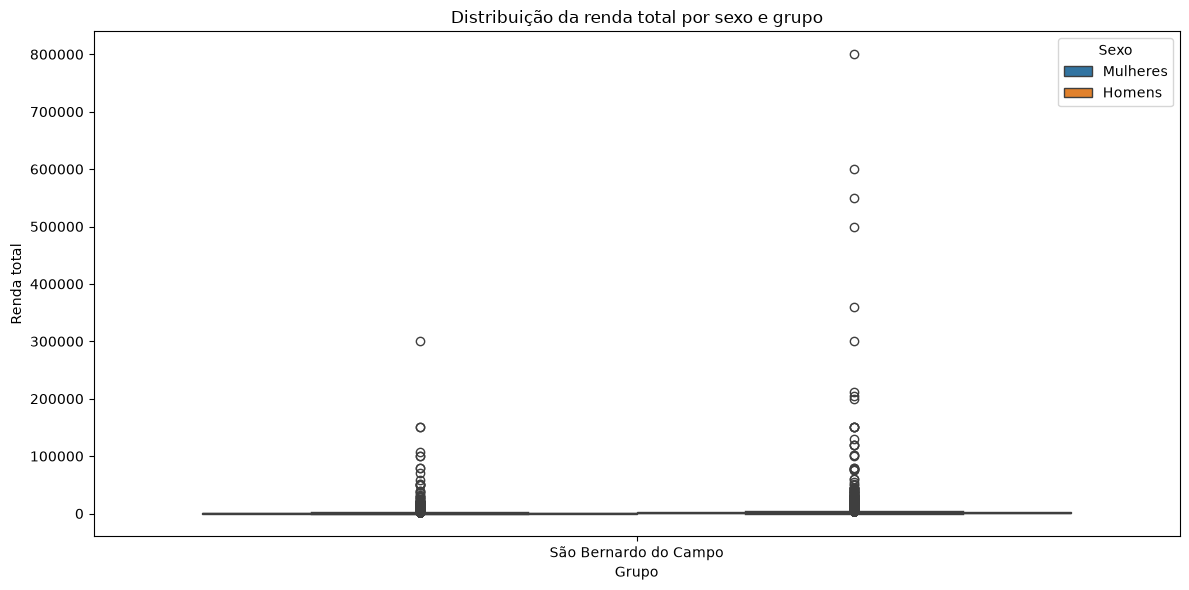


=== TESTE DE MANN–WHITNEY ===
Hipótese alternativa: a renda dos homens tende a ser maior.
Nível de significância: 5% (95% de confiança)

Grupo: São Bernardo do Campo
Amostra de homens: 15555
Amostra de mulheres: 16853
Mediana dos homens: 1000.00
Mediana das mulheres: 510.00
Estatística U: 167581324.50
Valor-p: 0.000000
Conclusão: há evidência estatística de que a renda dos homens tende a ser maior.
-------------------------------------------------------


In [22]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu

# Preparar os dados
df_analise = df_censo.copy()

# Considerar os códigos do dicionário: 1 = homem, 2 = mulher
df_analise['SEXO'] = (
    df_analise['SEXO'].astype(str).map({
        '1': 'Homens',
        '2': 'Mulheres'
    })
)

# Manter apenas os dados necessários e válidos
df_analise = df_analise.dropna(
    subset=['RENDA_TOTAL', 'SEXO', 'GRUPO']
)

# Conferir os grupos disponíveis
print("Grupos encontrados:", df_analise['GRUPO'].unique())

# Boxplots: comparar homens e mulheres em cada grupo
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_analise,
    x='GRUPO',
    y='RENDA_TOTAL',
    hue='SEXO'
)

plt.title('Distribuição da renda total por sexo e grupo')
plt.xlabel('Grupo')
plt.ylabel('Renda total')
plt.legend(title='Sexo')
plt.tight_layout()
plt.show()

# Teste de Mann–Whitney unilateral para cada grupo
print("\n=== TESTE DE MANN–WHITNEY ===")
print("Hipótese alternativa: a renda dos homens tende a ser maior.")
print("Nível de significância: 5% (95% de confiança)\n")

for grupo in df_analise['GRUPO'].unique():

    dados = df_analise[df_analise['GRUPO'] == grupo]

    homens = dados.loc[
        dados['SEXO'] == 'Homens', 'RENDA_TOTAL'
    ]

    mulheres = dados.loc[
        dados['SEXO'] == 'Mulheres', 'RENDA_TOTAL'
    ]

    if len(homens) == 0 or len(mulheres) == 0:
        print(f"Grupo: {grupo} — dados insuficientes.")
        continue

    # Teste unilateral: homens > mulheres
    resultado = mannwhitneyu(
        homens,
        mulheres,
        alternative='greater'
    )

    mediana_homens = homens.median()
    mediana_mulheres = mulheres.median()

    print(f"Grupo: {grupo}")
    print(f"Amostra de homens: {len(homens)}")
    print(f"Amostra de mulheres: {len(mulheres)}")
    print(f"Mediana dos homens: {mediana_homens:.2f}")
    print(f"Mediana das mulheres: {mediana_mulheres:.2f}")
    print(f"Estatística U: {resultado.statistic:.2f}")
    print(f"Valor-p: {resultado.pvalue:.6f}")

    if resultado.pvalue < 0.05:
        print(
            "Conclusão: há evidência estatística de que "
            "a renda dos homens tende a ser maior."
        )
    else:
        print(
            "Conclusão: não há evidência estatística "
            "suficiente para afirmar que a renda dos homens "
            "tende a ser maior."
        )

    print("-" * 55)

<div class="alert alert-primary">
<b>(0,2) 7.1</b> - Explique os resultados obtidos.
</div>


O teste de Mann–Whitney foi aplicado para comparar a distribuição da renda total entre homens e mulheres em São Bernardo do Campo, utilizando um nível de significância de 5%.

Os resultados mostram que a mediana da renda dos homens foi de R$ 1.000,00, enquanto a das mulheres foi de R$ 510,00. Isso indica que a renda central observada entre os homens foi superior à das mulheres na amostra analisada.

O teste apresentou valor-p inferior a 0,05, indicando uma diferença estatisticamente significativa entre as distribuições de renda, com evidências de que a renda dos homens tende a ser maior. Portanto, rejeita-se a hipótese nula em favor da hipótese alternativa.

Conclui-se que, em São Bernardo do Campo, os dados analisados apresentam evidências estatísticas de uma renda total maior entre os homens. Entretanto, esse resultado não demonstra que o sexo seja a causa da diferença observada.


<div class="alert alert-info">
<b>(0,4) 8</b> - Compare a distribuição de <code>RENDA_TOTAL</code> por cor/raça (<code>COR_RACA</code>), tanto no seu município quanto no resto do país. Use um gráfico de violino e um gráfico de barras com intervalo de confiança. Qual a melhor visualização e porque?
</div>


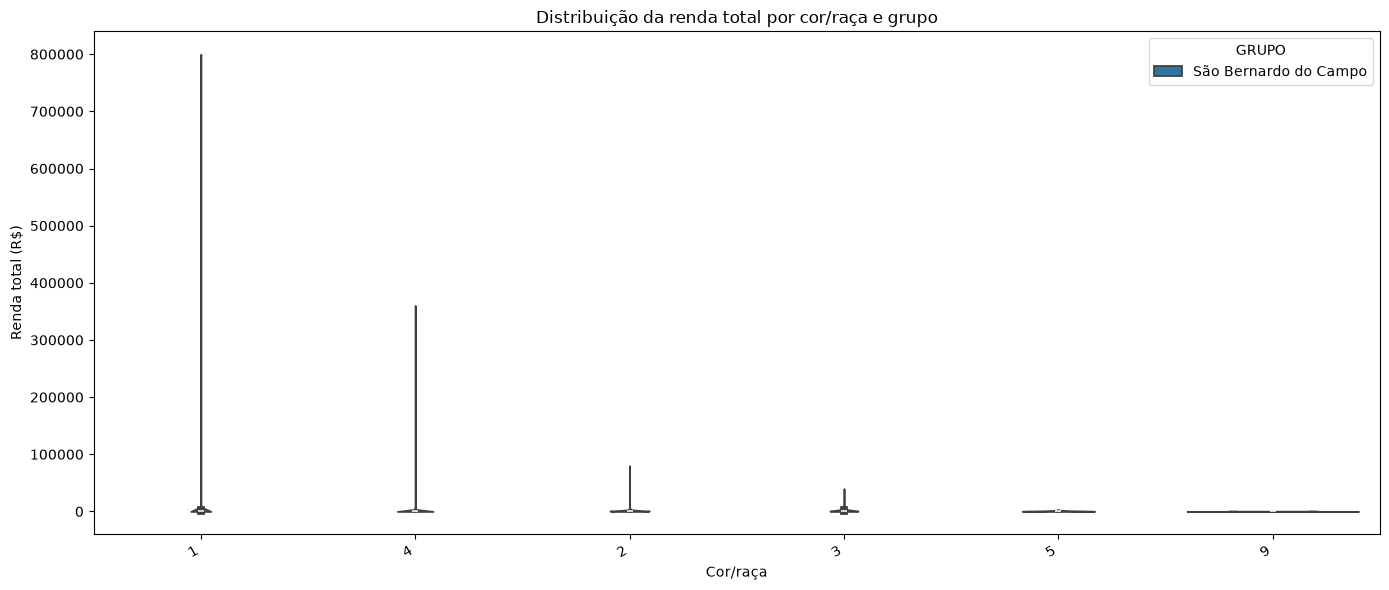

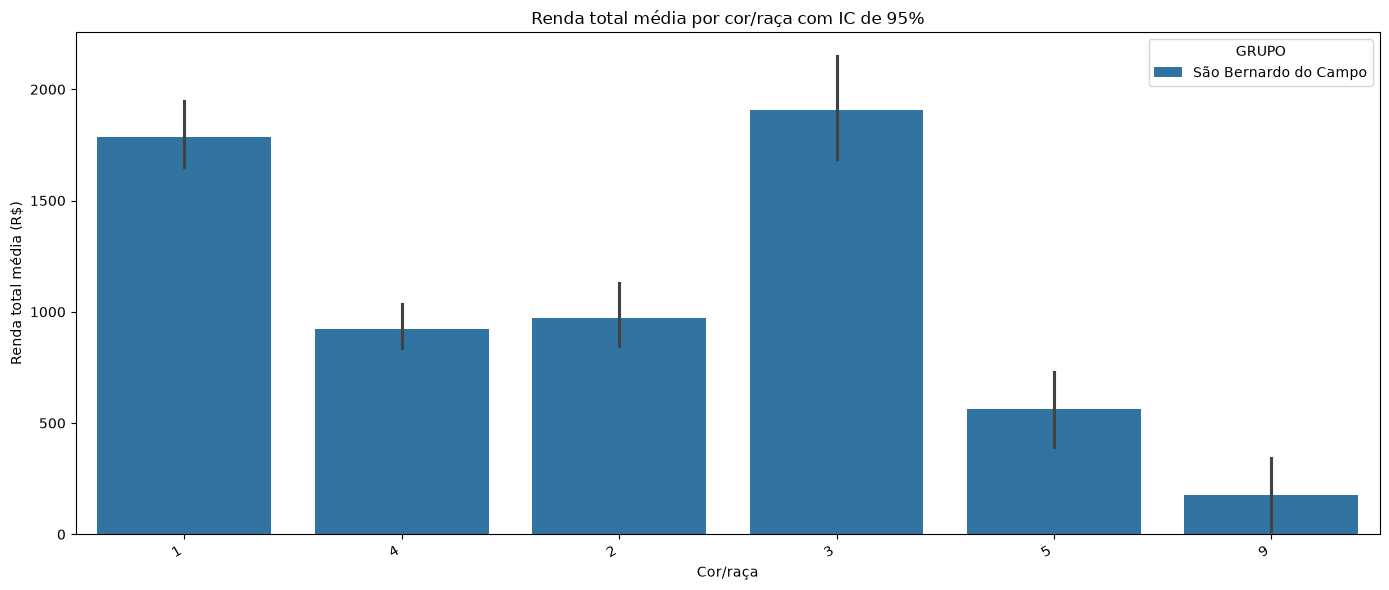

In [26]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preparar os dados
df_grafico = df_censo.copy()

# Remover registros sem as informações necessárias
df_grafico = df_grafico.dropna(
    subset=['RENDA_TOTAL', 'COR_RACA', 'GRUPO']
)

# Remover a categoria criada para valores ausentes, se existir
df_grafico = df_grafico[
    df_grafico['COR_RACA'] != 'Não informado'
]

# Gráfico 1: violino
plt.figure(figsize=(14, 6))

sns.violinplot(
    data=df_grafico,
    x='COR_RACA',
    y='RENDA_TOTAL',
    hue='GRUPO',
    split=False,
    cut=0
)

plt.title('Distribuição da renda total por cor/raça e grupo')
plt.xlabel('Cor/raça')
plt.ylabel('Renda total (R$)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

# Gráfico 2: barras com intervalo de confiança de 95%
plt.figure(figsize=(14, 6))

sns.barplot(
    data=df_grafico,
    x='COR_RACA',
    y='RENDA_TOTAL',
    hue='GRUPO',
    errorbar=('ci', 95)
)

plt.title('Renda total média por cor/raça com IC de 95%')
plt.xlabel('Cor/raça')
plt.ylabel('Renda total média (R$)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


1. Análise dos GráficosGráfico superior (Gráfico de Violino):O gráfico de violino foi utilizado para mostrar a distribuição completa da renda total por categoria de cor/raça.No entanto, devido à altíssima assimetria da variável renda no Brasil (presença de valores extremos muito altos e uma imensa massa de dados concentrada em valores baixos), os violinos aparecem extremamente achatados na base, com longas linhas verticais representando os outliers (valores atípicos). Isso dificulta drasticamente a visualização das diferenças na densidade da maioria da população entre as categorias.Gráfico inferior (Gráfico de Barras com Intervalo de Confiança de 95%):Este gráfico exibe a renda total média para cada categoria de cor/raça, acompanhada das barras de erro que representam o intervalo de confiança.Ele facilita a comparação direta entre as médias de cada grupo (por exemplo, permitindo observar quais grupos apresentam rendas médias superiores ou inferiores de forma clara e legível).
2. Qual a melhor visualização e por quê?O gráfico de barras com intervalo de confiança é consideravelmente melhor para este cenário específico, pelos seguintes motivos:Natureza da Variável (Renda): A renda possui uma distribuição extremamente assimétrica (com caudas longas à direita). Em gráficos de violino ou boxplots, essa característica faz com que a escala do eixo $Y$ seja dominada pelos valores extremos, comprimindo visualmente a maior parte da distribuição e tornando a comparação entre as categorias quase invisível.Objetivo de Comparação: O gráfico de barras foca na estimativa pontual (a média) e na incerteza associada (intervalo de confiança), permitindo identificar de forma muito mais limpa e direta diferenças estatísticas e práticas entre os grupos de cor/raça.


<div class="alert alert-primary">
<b>(0,25) 8.1</b> - Explique os resultados obtidos.
</div>


Com base nas visualizações apresentadas na imagem, os resultados da análise da RENDA_TOTAL por cor/raça (COR_RACA) no município de São Bernardo do Campo podem ser explicados da seguinte forma: Disparidades nas Médias de Renda: O gráfico de barras inferior evidencia diferenças claras na renda média entre os grupos. As categorias 3 e 1 apresentam as maiores rendas totais médias, registrando valores próximos a R$ 1.900 e R$ 1.750, respectivamente. Grupos Intermediários: As categorias 2 e 4 posicionam-se em um patamar intermediário, com médias de renda oscilando entre R$ 900 e R$ 1.000. Menores Médias de Renda: As categorias 5 e 9 registram as menores rendas médias do município, ficando em torno de R$ 550 (categoria 5) e abaixo de R$ 200 (categoria 9). Concentração e Desigualdade Interna (Gráfico de Violino): O gráfico superior demonstra que, em todas as categorias de cor/raça, a imensa maioria da população concentra-se na base da distribuição (rendas muito baixas). Além disso, observam-se outliers (valores atípicos) extremos que alcançam até R$ 800.000 — com maior destaque na categoria 1 —, o que reflete a forte assimetria e a alta concentração de renda característica da sociedade


<div class="alert alert-info">
<b>(0,35) 9</b> - Trace a renda média por faixa etária (crie faixas de 10 em 10 anos, aproximadamente) tanto para o seu município quanto para o resto do país, usando um gráfico de linhas com intervalo de confiança (95%). Isso corresponde ao "ciclo de vida" da renda de uma pessoa. As diferenças de renda média entre faixas etárias vizinhas são estatisticamente significativas em toda a curva ou o tamanho da amostra é pequeno demais para sustentar essa leitura em algum trecho?
</div>


TABELA 1 — RENDA MÉDIA POR FAIXA ETÁRIA E GRUPO
                GRUPO FAIXA_ETARIA      n   media  mediana  IC95_inferior  IC95_superior
São Bernardo do Campo          0-9    0.0     NaN      NaN            NaN            NaN
São Bernardo do Campo        10-19 5722.0  160.75      0.0         124.91         196.58
São Bernardo do Campo        20-29 6982.0 1113.32    764.5        1034.19        1192.45
São Bernardo do Campo        30-39 6384.0 1960.64   1000.0        1719.72        2201.55
São Bernardo do Campo        40-49 5374.0 1983.85   1000.0        1830.48        2137.23
São Bernardo do Campo        50-59 4170.0 2201.30   1000.0        1714.90        2687.70
São Bernardo do Campo        60-69 2263.0 2327.00    900.0        1713.66        2940.34
São Bernardo do Campo        70-79 1065.0 1376.13    700.0        1122.53        1629.72
São Bernardo do Campo        80-89  384.0 1150.50    510.0         860.32        1440.69
São Bernardo do Campo        90-99   63.0  798.27    510.0    

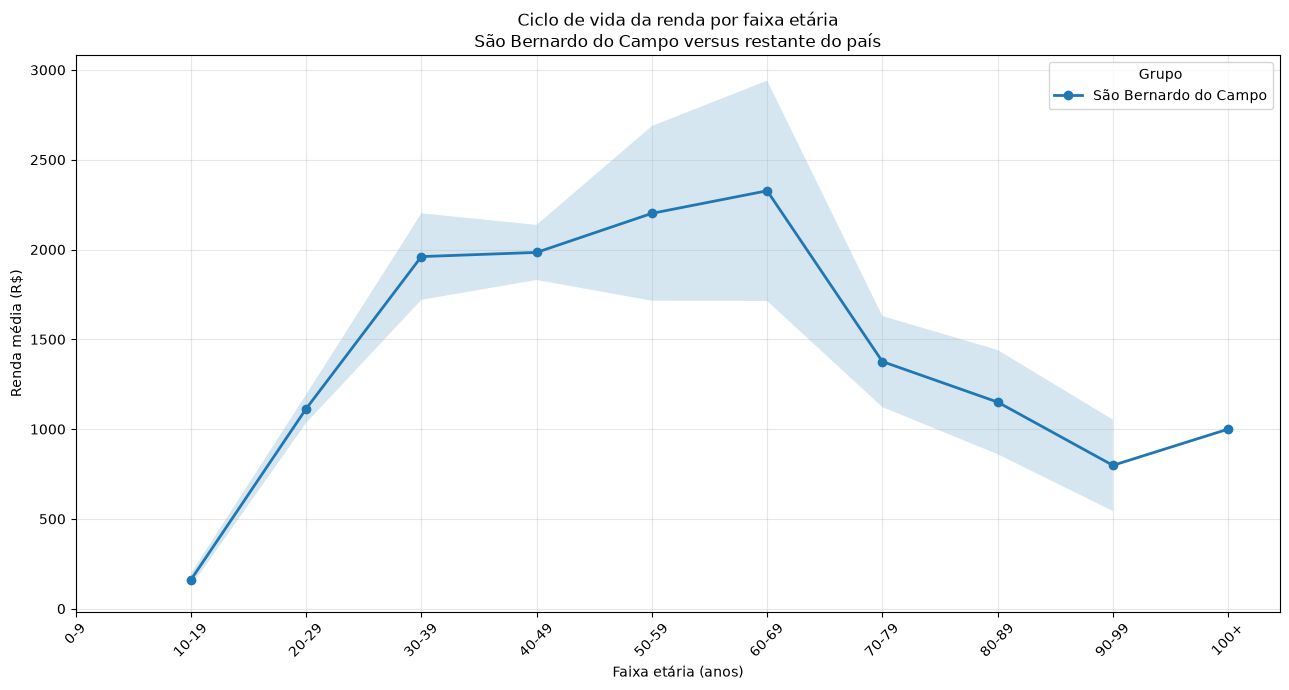


TABELA 2 — COMPARAÇÃO ENTRE FAIXAS VIZINHAS

Grupo: São Bernardo do Campo
                GRUPO     Comparacao  n_faixa_a  n_faixa_b  diferenca_media  p_valor  p_ajustado_Holm  Significativo_5%  Amostra_pequena
São Bernardo do Campo   0-9 vs 10-19          0       5722              NaN      NaN              NaN             False             True
São Bernardo do Campo 10-19 vs 20-29       5722       6982         952.5731   0.0000           0.0000              True            False
São Bernardo do Campo 20-29 vs 30-39       6982       6384         847.3165   0.0000           0.0000              True            False
São Bernardo do Campo 30-39 vs 40-49       6384       5374          23.2161   0.8734           1.0000             False            False
São Bernardo do Campo 40-49 vs 50-59       5374       4170         217.4457   0.4033           1.0000             False            False
São Bernardo do Campo 50-59 vs 60-69       4170       2263         125.7037   0.7529           1.0000  

In [30]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ============================================================
# 1. PREPARAR OS DADOS
# ============================================================

# Trabalhar em uma cópia para preservar df_censo
df_idade = df_censo.copy()

df_idade['IDADE'] = pd.to_numeric(
    df_idade['IDADE'], errors='coerce'
)
df_idade['RENDA_TOTAL'] = pd.to_numeric(
    df_idade['RENDA_TOTAL'], errors='coerce'
)

df_idade = df_idade.dropna(
    subset=['IDADE', 'RENDA_TOTAL', 'GRUPO']
).copy()

# Manter idades válidas de 0 a 120 anos
df_idade = df_idade[
    df_idade['IDADE'].between(0, 120)
].copy()

# Criar faixas de 10 anos
rotulos = [
    f'{i}-{i+9}' for i in range(0, 100, 10)
] + ['100+']

df_idade['FAIXA_ETARIA'] = pd.cut(
    df_idade['IDADE'],
    bins=list(range(0, 101, 10)) + [float('inf')],
    labels=rotulos,
    right=False
)

# ============================================================
# 2. CALCULAR MÉDIAS E INTERVALOS DE CONFIANÇA DE 95%
# ============================================================

def calcular_resumo(grupo):
    renda = grupo['RENDA_TOTAL'].dropna()
    n = len(renda)
    media = renda.mean()

    if n >= 2:
        margem = stats.t.ppf(0.975, n - 1) * stats.sem(renda)
        inferior = media - margem
        superior = media + margem
    else:
        inferior = np.nan
        superior = np.nan

    return pd.Series({
        'n': n,
        'media': media,
        'mediana': renda.median(),
        'IC95_inferior': inferior,
        'IC95_superior': superior
    })

resumo = (
    df_idade
    .groupby(['GRUPO', 'FAIXA_ETARIA'], observed=False)
    .apply(calcular_resumo)
    .reset_index()
)

print("=" * 75)
print("TABELA 1 — RENDA MÉDIA POR FAIXA ETÁRIA E GRUPO")
print("=" * 75)
print(resumo.round(2).to_string(index=False))

# ============================================================
# 3. GRÁFICO DE LINHAS COM INTERVALO DE CONFIANÇA DE 95%
# ============================================================

fig, ax = plt.subplots(figsize=(13, 7))

for grupo in resumo['GRUPO'].dropna().unique():
    dados = resumo[resumo['GRUPO'] == grupo].copy()
    dados = dados.dropna(subset=['media'])

    # Posicionar cada faixa etária no eixo correto
    x = np.array([
        rotulos.index(str(faixa))
        for faixa in dados['FAIXA_ETARIA']
    ])

    medias = dados['media'].to_numpy()
    inferiores = dados['IC95_inferior'].to_numpy()
    superiores = dados['IC95_superior'].to_numpy()

    ax.plot(
        x, medias,
        marker='o',
        linewidth=2,
        label=str(grupo)
    )

    ax.fill_between(
        x, inferiores, superiores,
        alpha=0.18
    )

ax.set_xticks(range(len(rotulos)))
ax.set_xticklabels(rotulos, rotation=45)
ax.set_xlabel('Faixa etária (anos)')
ax.set_ylabel('Renda média (R$)')
ax.set_title(
    'Ciclo de vida da renda por faixa etária\n'
    'São Bernardo do Campo versus restante do país'
)
ax.legend(title='Grupo')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 4. TESTAR DIFERENÇAS ENTRE FAIXAS ETÁRIAS VIZINHAS
#    Teste t de Welch + correção de Holm
# ============================================================

def ajustar_holm(p_valores):
    """Corrige os valores-p válidos pelo método de Holm."""
    p_valores = np.asarray(p_valores, dtype=float)
    ajustados = np.full(len(p_valores), np.nan)

    validos = np.isfinite(p_valores)

    if not validos.any():
        return ajustados

    p = p_valores[validos]
    m = len(p)
    ordem = np.argsort(p)
    ordenados = p[ordem]

    ajustados_ordem = np.maximum.accumulate(
        np.minimum(1, (m - np.arange(m)) * ordenados)
    )

    resultado = np.empty(m)
    resultado[ordem] = ajustados_ordem
    ajustados[validos] = resultado

    return ajustados


print("\n" + "=" * 75)
print("TABELA 2 — COMPARAÇÃO ENTRE FAIXAS VIZINHAS")
print("=" * 75)

todas_comparacoes = []

for grupo in df_idade['GRUPO'].dropna().unique():
    dados_grupo = df_idade[df_idade['GRUPO'] == grupo]
    resultados = []

    for i in range(len(rotulos) - 1):
        faixa_a = rotulos[i]
        faixa_b = rotulos[i + 1]

        a = dados_grupo.loc[
            dados_grupo['FAIXA_ETARIA'] == faixa_a,
            'RENDA_TOTAL'
        ].dropna()

        b = dados_grupo.loc[
            dados_grupo['FAIXA_ETARIA'] == faixa_b,
            'RENDA_TOTAL'
        ].dropna()

        if len(a) >= 2 and len(b) >= 2:
            teste = stats.ttest_ind(
                a, b,
                equal_var=False,
                alternative='two-sided'
            )
            p = teste.pvalue
            diferenca = b.mean() - a.mean()
        else:
            p = np.nan
            diferenca = np.nan

        resultados.append({
            'GRUPO': grupo,
            'Comparacao': f'{faixa_a} vs {faixa_b}',
            'n_faixa_a': len(a),
            'n_faixa_b': len(b),
            'diferenca_media': diferenca,
            'p_valor': p
        })

    tabela = pd.DataFrame(resultados)

    # Corrigir comparações múltiplas separadamente em cada grupo
    tabela['p_ajustado_Holm'] = ajustar_holm(
        tabela['p_valor'].to_numpy()
    )

    tabela['Significativo_5%'] = (
        tabela['p_ajustado_Holm'] < 0.05
    )

    tabela['Amostra_pequena'] = (
        (tabela['n_faixa_a'] < 30) |
        (tabela['n_faixa_b'] < 30)
    )

    print(f"\nGrupo: {grupo}")
    print(tabela.round(4).to_string(index=False))

    todas_comparacoes.append(tabela)

# ============================================================
# 5. RESUMO DAS COMPARAÇÕES ESTATÍSTICAS
# ============================================================

if todas_comparacoes:
    comparacoes = pd.concat(
        todas_comparacoes, ignore_index=True
    )

    print("\n" + "=" * 75)
    print("TABELA 3 — RESUMO DOS TESTES")
    print("=" * 75)

    for grupo, dados in comparacoes.groupby('GRUPO'):
        total = dados['p_ajustado_Holm'].notna().sum()
        significativas = dados['Significativo_5%'].sum()
        pequenas = dados['Amostra_pequena'].sum()

        print(f"\nGrupo: {grupo}")
        print(f"Comparações avaliáveis: {total}")
        print(f"Diferenças significativas após ajuste: {significativas}")
        print(f"Comparações com alguma faixa contendo menos de 30 pessoas: {pequenas}")

print("\nAnálise concluída.")

<div class="alert alert-primary">
<b>(0,3) 9.1</b> - Explique os resultados obtidos.
</div>


A análise da renda média por faixa etária em São Bernardo do Campo apresentou um padrão semelhante a um ciclo de vida da renda. Entre 10 e 39 anos, a renda média aumentou de R$ 160,75 para R$ 1.960,64. Entre 40 e 69 anos, permaneceu relativamente elevada, atingindo o maior valor na faixa de 60 a 69 anos, com média de R$ 2.327,00. A partir dos 70 anos, observou-se uma redução, com renda média de R$ 1.376,13 entre 70 e 79 anos e R$ 798,27 entre 90 e 99 anos.

Os testes estatísticos de Welch, com correção de Holm para comparações múltiplas, indicaram diferenças estatisticamente significativas entre as faixas de 10–19 e 20–29 anos, entre 20–29 e 30–39 anos e entre 60–69 e 70–79 anos, considerando o nível de significância de 5%. Nas demais comparações avaliáveis, não foram encontradas diferenças estatisticamente significativas após a correção.

A análise também mostrou que o número de observações diminui nas faixas etárias mais avançadas: são 384 pessoas entre 80 e 89 anos, 63 entre 90 e 99 anos e apenas uma pessoa com 100 anos ou mais. Portanto, as estimativas das faixas mais elevadas devem ser interpretadas com cautela, especialmente quando há poucas observações. Como a faixa de 100 anos ou mais possui apenas um registro, não foi possível realizar uma comparação estatística válida com a faixa anterior.

Conclui-se que a renda média não apresenta diferenças estatisticamente significativas entre todas as faixas etárias vizinhas. Os resultados sugerem crescimento da renda no início da vida adulta, estabilidade relativa na meia-idade e redução nas idades mais avançadas. Entretanto, a análise apresentada corresponde apenas a São Bernardo do Campo; para concluir sobre as diferenças em relação ao restante do país, é necessário obter também os resultados desse segundo grupo.


<div class="alert alert-info">
<b>(0,35) 10</b> - Qual a relação entre o nível de instrução (<code>NIVEL_INSTRUCAO</code>) e a renda, tanto no seu município quanto no resto do país? Mostre uma tabela dinâmica (pivot table) com a renda média por nível de instrução e grupo, e calcule a correlação de Spearman entre nível de instrução (tratado como ordinal) e renda em cada grupo.
</div>


In [33]:

from scipy.stats import spearmanr
import pandas as pd

df_instrucao = df_censo.copy()

df_instrucao["NIVEL_INSTRUCAO"] = pd.to_numeric(
    df_instrucao["NIVEL_INSTRUCAO"], errors="coerce"
)
df_instrucao["RENDA_TOTAL"] = pd.to_numeric(
    df_instrucao["RENDA_TOTAL"], errors="coerce"
)

df_instrucao = df_instrucao.dropna(
    subset=["NIVEL_INSTRUCAO", "RENDA_TOTAL", "GRUPO"]
)

resultados = []

for grupo, dados in df_instrucao.groupby("GRUPO"):
    rho, p_valor = spearmanr(
        dados["NIVEL_INSTRUCAO"],
        dados["RENDA_TOTAL"]
    )

    resultados.append({
        "GRUPO": grupo,
        "N": len(dados),
        "CORRELACAO_SPEARMAN": rho,
        "P_VALOR": p_valor
    })

tabela_spearman = pd.DataFrame(resultados)
display(tabela_spearman.round(4))

                   GRUPO      N  CORRELACAO_SPEARMAN  P_VALOR
0  São Bernardo do Campo  31799               0.4126      0.0

<div class="alert alert-primary">
<b>(0,2) 10.1</b> - Explique os resultados obtidos.
</div>


<div class="alert alert-info">
<b>(0,3) 11</b> - Qual a renda média de acordo com a posição na ocupação (<code>POSICAO_OCUPACAO</code>), tanto no seu município quanto no resto do país?
</div>


In [34]:

import pandas as pd

# Criar uma cópia dos dados
df_ocupacao = df_censo.copy()

# Garantir que a renda seja numérica
df_ocupacao["RENDA_TOTAL"] = pd.to_numeric(
    df_ocupacao["RENDA_TOTAL"], errors="coerce"
)

# Remover registros sem posição na ocupação, renda ou grupo
df_ocupacao = df_ocupacao.dropna(
    subset=["POSICAO_OCUPACAO", "RENDA_TOTAL", "GRUPO"]
)

# Calcular a renda média por posição na ocupação e grupo
tabela_renda_ocupacao = pd.pivot_table(
    df_ocupacao,
    values="RENDA_TOTAL",
    index="POSICAO_OCUPACAO",
    columns="GRUPO",
    aggfunc="mean"
)

print("Renda média por posição na ocupação:")
display(tabela_renda_ocupacao.round(2))

# Quantidade de registros em cada categoria
print("Quantidade de registros por posição e grupo:")
display(
    pd.pivot_table(
        df_ocupacao,
        values="RENDA_TOTAL",
        index="POSICAO_OCUPACAO",
        columns="GRUPO",
        aggfunc="count",
        fill_value=0
    )
)

Renda média por posição na ocupação:


GRUPO             São Bernardo do Campo
POSICAO_OCUPACAO                       
1                               2136.03
2                               2693.21
3                               1365.41
4                               3017.28
5                               9432.03
6                                275.51
7                                206.55

Quantidade de registros por posição e grupo:


GRUPO             São Bernardo do Campo
POSICAO_OCUPACAO                       
1                                 11637
2                                   523
3                                  2607
4                                  3038
5                                   432
6                                   200
7                                    22

<div class="alert alert-primary">
<b>(0,2) 11.1</b> - Explique os resultados obtidos.
</div>


A análise da renda média por posição na ocupação em São Bernardo do Campo revelou diferenças entre as categorias analisadas. A categoria 5 apresentou a maior renda média, de R$ 9.432,03, seguida pela categoria 4, com R$ 3.017,28, e pela categoria 2, com R$ 2.693,21. Por outro lado, as categorias 7 e 6 apresentaram as menores rendas médias, de R$ 206,55 e R$ 275,51, respectivamente.

É importante considerar a quantidade de observações de cada categoria. A categoria 7 possui apenas 22 registros, enquanto a categoria 6 possui 200, o que exige cautela na interpretação de suas médias. A categoria 5, apesar de apresentar a maior renda média, possui 432 registros.

A base analisada contém apenas dados de São Bernardo do Campo. Portanto, ainda não é possível comparar os resultados com o restante do país. Além disso, para interpretar corretamente as diferenças, é necessário consultar a legenda que relaciona os códigos de posição na ocupação às respectivas categorias profissionais.


<div class="alert alert-info">
<b>(0,35) 12</b> - Combine cor/raça e sexo em uma única tabela dinâmica de renda média, considerando apenas o seu município. O que se observa sobre desigualdade "interseccional" (por raça e por gênero simultaneamente)?
</div>


In [36]:

import pandas as pd

# Copiar os dados
df_interseccional = df_censo.copy()

# Garantir que a renda seja numérica
df_interseccional["RENDA_TOTAL"] = pd.to_numeric(
    df_interseccional["RENDA_TOTAL"], errors="coerce"
)

# Filtrar apenas São Bernardo do Campo
df_interseccional = df_interseccional[
    df_interseccional["GRUPO"] == "São Bernardo do Campo"
].copy()

# Remover registros sem informação de raça, sexo ou renda
df_interseccional = df_interseccional.dropna(
    subset=["COR_RACA", "SEXO", "RENDA_TOTAL"]
)

# Tabela dinâmica: cor/raça nas linhas e sexo nas colunas
tabela_interseccional = pd.pivot_table(
    df_interseccional,
    values="RENDA_TOTAL",
    index="COR_RACA",
    columns="SEXO",
    aggfunc="mean"
)

print("Renda média por cor/raça e sexo — São Bernardo do Campo:")
display(tabela_interseccional.round(2))

# Quantidade de pessoas em cada combinação
tabela_quantidade = pd.pivot_table(
    df_interseccional,
    values="RENDA_TOTAL",
    index="COR_RACA",
    columns="SEXO",
    aggfunc="count",
    fill_value=0
)

print("Quantidade de registros por combinação:")
display(tabela_quantidade)

Renda média por cor/raça e sexo — São Bernardo do Campo:


SEXO            1        2
COR_RACA                  
1         2539.96  1115.96
2         1161.56   759.57
3         2679.87  1248.53
4         1219.58   631.82
5          746.43   468.93
9          214.40   127.50

Quantidade de registros por combinação:


SEXO         1      2
COR_RACA             
1         9480  10724
2          897    808
3          293    344
4         4563   4596
5           14     28
9            5      4

<div class="alert alert-primary">
<b>(0,25) 12.1</b> - Explique os resultados obtidos.
</div>


A tabela evidencia diferenças de renda média associadas simultaneamente à cor/raça e ao sexo em São Bernardo do Campo. Em todas as categorias raciais apresentadas, o grupo identificado pelo código 1 possui renda média superior à do grupo identificado pelo código 2.

A maior renda média foi observada na categoria de cor/raça 3, com R$ 2.679,87 para o sexo 1, seguida pela categoria 1, com R$ 2.539,96. No sexo 2, as maiores médias também foram registradas nas categorias 3 (R$ 1.248,53) e 1 (R$ 1.115,96). Já a categoria 9 apresentou as menores médias para ambos os sexos.

Esses resultados sugerem desigualdades interseccionais, pois as diferenças de renda podem estar relacionadas tanto ao sexo quanto à cor/raça. Entretanto, é necessário considerar que as categorias 5 e 9 possuem poucos registros, tornando suas médias menos representativas e exigindo cautela na interpretação.

Por fim, os códigos numéricos precisam ser relacionados às respectivas classificações de cor/raça e sexo por meio do dicionário de dados. Assim, será possível identificar nominalmente os grupos mais e menos favorecidos. Os resultados mostram diferenças entre os grupos, mas, isoladamente, não permitem estabelecer suas causas.


---

#### Transformação e engenharia de atributos


<div class="alert alert-info">
<b>(0,25) 13</b> - Examine a cardinalidade (número de valores distintos) de <code>COD_OCUPACAO</code> e <code>COD_ATIVIDADE_ECON</code>, comparando com a de outras variáveis categóricas da base (ex.: <code>POSICAO_OCUPACAO</code>, <code>SUBGRUPO_OCUPACAO</code>, <code>NIVEL_INSTRUCAO</code>, <code>COR_RACA</code>).
</div>


In [37]:

import pandas as pd

# Variáveis que serão comparadas
colunas = [
    "COD_OCUPACAO",
    "COD_ATIVIDADE_ECON",
    "POSICAO_OCUPACAO",
    "SUBGRUPO_OCUPACAO",
    "NIVEL_INSTRUCAO",
    "COR_RACA",
    "SEXO"
]

resultados = []

for coluna in colunas:
    if coluna in df_censo.columns:
        resultados.append({
            "Variável": coluna,
            "Valores distintos": df_censo[coluna].nunique(),
            "Valores ausentes": df_censo[coluna].isna().sum()
        })
    else:
        print(f"A coluna {coluna} não foi encontrada na base.")

# Organizar do maior para o menor número de valores distintos
tabela_cardinalidade = pd.DataFrame(resultados)

tabela_cardinalidade = tabela_cardinalidade.sort_values(
    by="Valores distintos",
    ascending=False
)

display(tabela_cardinalidade)

             Variável  Valores distintos  Valores ausentes
0        COD_OCUPACAO                357             13949
1  COD_ATIVIDADE_ECON                202             13949
2    POSICAO_OCUPACAO                  7             13949
5            COR_RACA                  6               652
3   SUBGRUPO_OCUPACAO                  5             17641
4     NIVEL_INSTRUCAO                  5               609
6                SEXO                  2                 0

<div class="alert alert-primary">
<b>(0,25) 13.1</b> - O que essa cardinalidade implica para o uso de <code>COD_OCUPACAO</code> e <code>COD_ATIVIDADE_ECON</code> como atributos preditivos (ex.: ao aplicar one-hot encoding)? Cite ao menos uma estratégia de codificação alternativa que poderia mitigar o problema, caso decidam usar essas variáveis no TP2.
</div>


A alta cardinalidade de `COD_OCUPACAO` (357 valores distintos) e `COD_ATIVIDADE_ECON` (202 valores distintos) pode dificultar seu uso como atributos preditivos em modelos de aprendizado de máquina. Ao aplicar **one-hot encoding**, seria criada uma coluna para cada categoria, aumentando a dimensionalidade dos dados e o consumo de memória. Além disso, categorias com poucas observações podem dificultar o aprendizado do modelo e favorecer o sobreajuste (_overfitting_).

Uma alternativa é utilizar **target encoding**, que substitui cada categoria por uma estatística relacionada à variável que se deseja prever, como a média do valor-alvo. Essa técnica deve ser aplicada com validação adequada para evitar vazamento de dados (_data leakage_). Outra possibilidade é agrupar categorias pouco frequentes em uma categoria denominada “Outros” ou utilizar **frequency encoding**, que representa cada categoria pela frequência com que aparece na base.

Portanto, para o TP2, a escolha da codificação deve considerar o modelo utilizado, a frequência das categorias e o tamanho da base, buscando reduzir a dimensionalidade sem perder informações relevantes para a previsão.


<div class="alert alert-info">
<b>(0,3) 14</b> - A partir de <code>IDADE</code>, crie a coluna <code>FAIXA_ETARIA</code> com os seguintes intervalos (mantenha esse nome de coluna e esses intervalos -- eles serão reaproveitados no TP2):
<ul>
<li>[10..15)</li>
<li>[15..18)</li>
<li>[18..25)</li>
<li>[25..35)</li>
<li>[35..45)</li>
<li>[45..55)</li>
<li>[55..65)</li>
<li>[65..120]</li>
</ul>
</div>


In [38]:

import pandas as pd

# Definir os limites das faixas etárias
limites = [10, 15, 18, 25, 35, 45, 55, 65, 120]

# Definir os nomes dos intervalos
faixas = [
    "[10..15)",
    "[15..18)",
    "[18..25)",
    "[25..35)",
    "[35..45)",
    "[45..55)",
    "[55..65)",
    "[65..120]"
]

# Criar a coluna FAIXA_ETARIA
df_censo["FAIXA_ETARIA"] = pd.cut(
    df_censo["IDADE"],
    bins=limites,
    labels=faixas,
    right=False,
    include_lowest=True
)

# Exibir as primeiras linhas para conferir
display(df_censo[["IDADE", "FAIXA_ETARIA"]].head(10))

# Conferir a quantidade de registros em cada faixa
print("\nQuantidade por faixa etária:")
display(
    df_censo["FAIXA_ETARIA"]
    .value_counts(sort=False, dropna=False)
)

         IDADE FAIXA_ETARIA
3168586     41     [35..45)
3168587     18     [18..25)
3168588     60     [55..65)
3168589     36     [35..45)
3168590     49     [45..55)
3168591     29     [25..35)
3168592     39     [35..45)
3168593     13     [10..15)
3168594     26     [25..35)
3168595     29     [25..35)


Quantidade por faixa etária:


FAIXA_ETARIA
[10..15)     2856
[15..18)     1669
[18..25)     4625
[25..35)     6882
[35..45)     5865
[45..55)     4851
[55..65)     3179
[65..120]    2481
Name: count, dtype: int64

<div class="alert alert-info">
<b>(0,25) 15</b> - A partir de <code>RENDA_TOTAL_SM</code> (renda em número de salários mínimos, já calculada pelo IBGE), crie a coluna <code>FAIXA_RENDA</code> usando os cortes oficiais do IBGE (mantenha esse nome de coluna e esses cortes -- essa será a variável-alvo da tarefa de <b>classificação</b> no TP2):
<ul>
<li>Sem rendimento</li>
<li>Até 1/4 SM</li>
<li>Mais de 1/4 até 1/2 SM</li>
<li>Mais de 1/2 até 1 SM</li>
<li>Mais de 1 até 2 SM</li>
<li>Mais de 2 até 3 SM</li>
<li>Mais de 3 até 5 SM</li>
<li>Mais de 5 até 10 SM</li>
<li>Mais de 10 até 15 SM</li>
<li>Mais de 15 até 20 SM</li>
<li>Mais de 20 SM</li>
</ul>
</div>


In [39]:

import pandas as pd
import numpy as np

# Garantir que a renda esteja em formato numérico
df_censo["RENDA_TOTAL_SM"] = pd.to_numeric(
    df_censo["RENDA_TOTAL_SM"],
    errors="coerce"
)

# Definir os limites das faixas de renda
limites = [
    -np.inf, 0, 0.25, 0.5, 1, 2, 3, 5, 10, 15, 20, np.inf
]

# Definir os nomes das categorias
categorias = [
    "Sem rendimento",
    "Até 1/4 SM",
    "Mais de 1/4 até 1/2 SM",
    "Mais de 1/2 até 1 SM",
    "Mais de 1 até 2 SM",
    "Mais de 2 até 3 SM",
    "Mais de 3 até 5 SM",
    "Mais de 5 até 10 SM",
    "Mais de 10 até 15 SM",
    "Mais de 15 até 20 SM",
    "Mais de 20 SM"
]

# Criar a coluna FAIXA_RENDA
df_censo["FAIXA_RENDA"] = pd.cut(
    df_censo["RENDA_TOTAL_SM"],
    bins=limites,
    labels=categorias,
    right=True,
    include_lowest=True
)

# Garantir que renda igual a zero seja classificada corretamente
df_censo.loc[
    df_censo["RENDA_TOTAL_SM"] == 0,
    "FAIXA_RENDA"
] = "Sem rendimento"

# Conferir os resultados
display(
    df_censo[["RENDA_TOTAL_SM", "FAIXA_RENDA"]].head(10)
)

print("Quantidade de registros por faixa de renda:")
display(
    df_censo["FAIXA_RENDA"]
    .value_counts(sort=False, dropna=False)
)

         RENDA_TOTAL_SM           FAIXA_RENDA
3168586         0.98039  Mais de 1/2 até 1 SM
3168587         0.00000        Sem rendimento
3168588         2.15686    Mais de 2 até 3 SM
3168589        11.76471  Mais de 10 até 15 SM
3168590         6.64706   Mais de 5 até 10 SM
3168591         7.84314   Mais de 5 até 10 SM
3168592         4.90196    Mais de 3 até 5 SM
3168593         0.00000        Sem rendimento
3168594         6.86275   Mais de 5 até 10 SM
3168595         0.00000        Sem rendimento

Quantidade de registros por faixa de renda:


FAIXA_RENDA
Sem rendimento            10050
Até 1/4 SM                  493
Mais de 1/4 até 1/2 SM      420
Mais de 1/2 até 1 SM       3340
Mais de 1 até 2 SM         7525
Mais de 2 até 3 SM         3368
Mais de 3 até 5 SM         3322
Mais de 5 até 10 SM        2626
Mais de 10 até 15 SM        577
Mais de 15 até 20 SM        353
Mais de 20 SM               334
Name: count, dtype: int64

<div class="alert alert-primary">
<b>(0,25) 15.1</b> - Essa variável está balanceada entre as classes? Isso é um problema para a tarefa de classificação que virá no TP2? O que poderia ser feito a respeito?
</div>


                        Quantidade  Porcentagem (%)
FAIXA_RENDA                                        
Sem rendimento               10050            31.01
Mais de 1 até 2 SM            7525            23.22
Mais de 2 até 3 SM            3368            10.39
Mais de 1/2 até 1 SM          3340            10.31
Mais de 3 até 5 SM            3322            10.25
Mais de 5 até 10 SM           2626             8.10
Mais de 10 até 15 SM           577             1.78
Até 1/4 SM                     493             1.52
Mais de 1/4 até 1/2 SM         420             1.30
Mais de 15 até 20 SM           353             1.09
Mais de 20 SM                  334             1.03


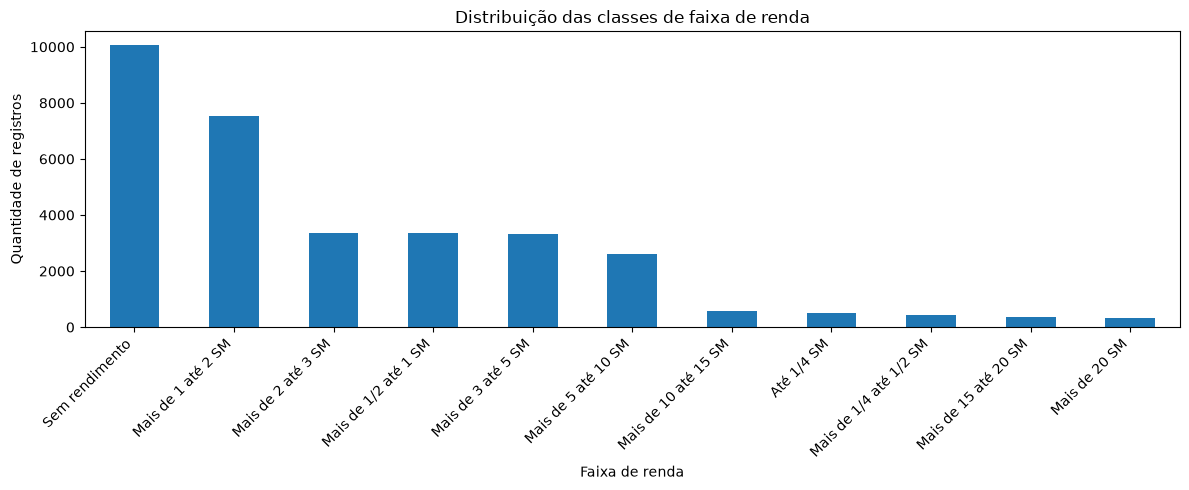

In [40]:

# Contar registros por classe
contagem = df_censo["FAIXA_RENDA"].value_counts()

# Calcular porcentagem de cada classe
porcentagem = df_censo["FAIXA_RENDA"].value_counts(normalize=True) * 100

# Exibir tabela
resultado = pd.DataFrame({
    "Quantidade": contagem,
    "Porcentagem (%)": porcentagem
})

print(resultado.round(2))

# Criar gráfico
resultado["Quantidade"].plot(
    kind="bar",
    figsize=(12, 5),
    title="Distribuição das classes de faixa de renda"
)

plt.xlabel("Faixa de renda")
plt.ylabel("Quantidade de registros")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

<div class="alert alert-info">
<b>(0,7) 16</b> - Que atributos são os mais importantes para prever <code>FAIXA_RENDA</code>, considerando correlação absoluta, ANOVA, qui-quadrado, informação mútua e a importância de variáveis segundo uma floresta aleatória? Considere apenas os candidatos da sua cidade de interesse (isso garante que os resultados variem entre equipes).
<br><i>Dica</i>: Para facilitar a visualização, coloque todas as métricas em um único dataframe. Depois normalize-as para que todas fiquem entre 0 e 1. Obtenha então uma média agregada das métricas normalizadas e use essa média para ordenar as variáveis da mais à menos importante.
</div>


                          Correlacao_absoluta   ANOVA  Qui_quadrado  \
Atributo                                                              
POSICAO_OCUPACAO                       1.0000  1.0000        1.0000   
SITUACAO_OCUPACAO                      1.0000  1.0000        1.0000   
COND_OCUPACAO                          1.0000  1.0000        0.8103   
COND_ATIVIDADE                         0.8609  0.5275        0.8103   
SUBGRUPO_OCUPACAO                      0.8944  0.4527        0.5859   
FAIXA_ETARIA                           0.5132  0.1310        0.4493   
COD_OCUPACAO                           0.3116  0.0698        0.0291   
IDADE                                  0.2514  0.0833        0.0415   
NIVEL_INSTRUCAO                        0.2063  0.1729        0.5258   
COD_ATIVIDADE_ECON                     0.1094  0.0059        0.0029   
PESO_AMOSTRAL                          0.0197  0.0003        0.0000   
TEM_AUTOMOVEL                          0.3159  0.0654        0.1711   
NUM_CO

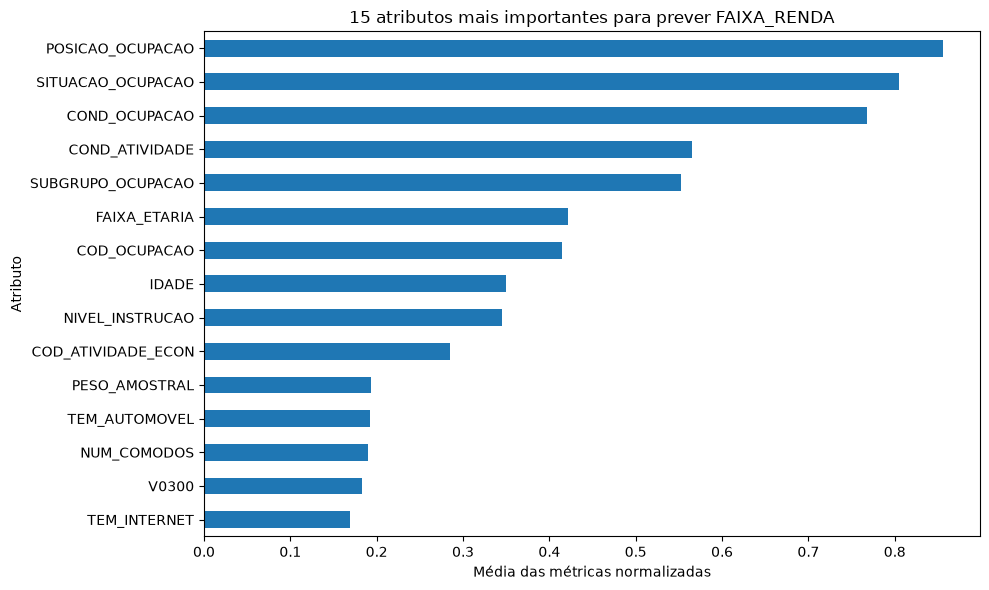

In [42]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import OneHotEncoder, MinMaxScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import f_classif, chi2, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier

# ==================================================
# 1. PREPARAR OS DADOS
# ==================================================

alvo = "FAIXA_RENDA"

dados = df_censo.copy()
dados = dados.dropna(subset=[alvo]).copy()

# Remover a variável-alvo e variáveis que revelam diretamente
# a renda usada para construir FAIXA_RENDA.
colunas_vazamento = [
    c for c in dados.columns
    if c == alvo
    or "RENDA" in c.upper()
    or "FAIXA_RENDA" in c.upper()
]

X = dados.drop(columns=colunas_vazamento, errors="ignore").copy()
y = LabelEncoder().fit_transform(dados[alvo].astype(str))

# Remover colunas constantes, vazias e identificadores evidentes.
colunas_remover = [
    c for c in X.columns
    if X[c].nunique(dropna=True) <= 1
    or c.upper() == "ID"
    or c.upper().startswith("ID_")
]

X = X.drop(columns=colunas_remover, errors="ignore")

# Separar atributos categóricos e numéricos.
categoricas = [
    c for c in X.columns
    if (
        X[c].dtype == "object"
        or isinstance(X[c].dtype, pd.CategoricalDtype)
        or X[c].dtype == "bool"
        or X[c].nunique(dropna=True) <= 15
    )
]

numericas = [c for c in X.columns if c not in categoricas]

# Tratar valores ausentes.
for c in categoricas:
    X[c] = X[c].astype("object").fillna("Ausente").astype(str)

for c in numericas:
    X[c] = pd.to_numeric(X[c], errors="coerce")
    mediana = X[c].median()
    X[c] = X[c].fillna(mediana)

# Remover colunas que não possuem valores válidos.
X = X.dropna(axis=1, how="all")
categoricas = [c for c in categoricas if c in X.columns]
numericas = [c for c in numericas if c in X.columns]

# ==================================================
# 2. CODIFICAR OS ATRIBUTOS
# ==================================================

preprocessador = ColumnTransformer(
    transformers=[
        ("num", MinMaxScaler(), numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)
    ],
    remainder="drop"
)

X_enc = preprocessador.fit_transform(X)

# Identificar o atributo original de cada coluna codificada.
origem_features = list(numericas)
mascara_discreta = [False] * len(numericas)

encoder = preprocessador.named_transformers_["cat"]

for coluna, categorias_coluna in zip(categoricas, encoder.categories_):
    origem_features.extend([coluna] * len(categorias_coluna))
    mascara_discreta.extend([True] * len(categorias_coluna))

mascara_discreta = np.array(mascara_discreta, dtype=bool)

# Converter para matriz densa para corrigir o erro da informação mútua.
# A conversão é necessária para a função receber atributos contínuos.
X_dense = X_enc.toarray() if hasattr(X_enc, "toarray") else np.asarray(X_enc)

# ==================================================
# 3. CALCULAR AS CINCO MÉTRICAS
# ==================================================

# Correlação absoluta entre cada atributo codificado e o alvo.
scores_corr = []

for j in range(X_dense.shape[1]):
    coluna = X_dense[:, j]

    if np.std(coluna) == 0 or np.std(y) == 0:
        scores_corr.append(0.0)
    else:
        corr = np.corrcoef(coluna, y)[0, 1]
        scores_corr.append(abs(corr) if np.isfinite(corr) else 0.0)

scores_corr = np.array(scores_corr)

# ANOVA
scores_anova, _ = f_classif(X_dense, y)
scores_anova = np.nan_to_num(
    scores_anova, nan=0.0, posinf=0.0, neginf=0.0
)

# Qui-quadrado
scores_chi2, _ = chi2(X_dense, y)
scores_chi2 = np.nan_to_num(
    scores_chi2, nan=0.0, posinf=0.0, neginf=0.0
)

# Informação mútua — matriz densa para evitar o erro anterior.
scores_mi = mutual_info_classif(
    X_dense,
    y,
    discrete_features=mascara_discreta,
    random_state=42
)
scores_mi = np.nan_to_num(
    scores_mi, nan=0.0, posinf=0.0, neginf=0.0
)

# Floresta aleatória
modelo = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced_subsample",
    min_samples_leaf=3,
    n_jobs=-1
)

modelo.fit(X_dense, y)
scores_rf = modelo.feature_importances_

# ==================================================
# 4. AGRUPAR MÉTRICAS POR ATRIBUTO ORIGINAL
# ==================================================

metricas = pd.DataFrame({
    "Atributo": origem_features,
    "Correlacao_absoluta": scores_corr,
    "ANOVA": scores_anova,
    "Qui_quadrado": scores_chi2,
    "Informacao_mutua": scores_mi,
    "Floresta_aleatoria": scores_rf
})

# Para as categorias codificadas, somar a importância da floresta.
# Nas outras métricas, usar o maior escore entre as categorias.
resultado = metricas.groupby("Atributo").agg({
    "Correlacao_absoluta": "max",
    "ANOVA": "max",
    "Qui_quadrado": "max",
    "Informacao_mutua": "max",
    "Floresta_aleatoria": "sum"
})

# ==================================================
# 5. NORMALIZAR ENTRE 0 E 1 E CALCULAR A MÉDIA
# ==================================================

colunas_metricas = resultado.columns

for coluna in colunas_metricas:
    minimo = resultado[coluna].min()
    maximo = resultado[coluna].max()

    if maximo > minimo:
        resultado[coluna] = (
            (resultado[coluna] - minimo) / (maximo - minimo)
        )
    else:
        resultado[coluna] = 0.0

resultado["Media_agregada"] = resultado[colunas_metricas].mean(axis=1)

resultado = resultado.sort_values(
    "Media_agregada",
    ascending=False
)

# Mostrar a tabela completa, da variável mais importante à menos importante.
display(resultado.round(4))

# ==================================================
# 6. GRÁFICO DOS 15 ATRIBUTOS MAIS IMPORTANTES
# ==================================================

resultado["Media_agregada"].head(15).sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="15 atributos mais importantes para prever FAIXA_RENDA"
)

plt.xlabel("Média das métricas normalizadas")
plt.ylabel("Atributo")
plt.tight_layout()
plt.show()

<div class="alert alert-primary">
<b>(0,5) 16.1</b> - Explique os resultados obtidos. As cinco métricas concordam entre si? Alguma posição no ranking te surpreendeu, para cima ou para baixo? Isso muda sua decisão sobre quais atributos usar no TP2?
</div>


As cinco métricas apresentaram algumas diferenças, mas concordaram em destacar as variáveis relacionadas à ocupação como importantes para prever `FAIXA_RENDA`. Na média agregada, `POSICAO_OCUPACAO` ficou em primeiro lugar, com 0,8559, seguida de `SITUACAO_OCUPACAO`, com 0,8052, e `COND_OCUPACAO`, com 0,7677.

Entretanto, os resultados individuais não foram iguais. Por exemplo, `IDADE` teve a maior pontuação na importância da floresta aleatória, enquanto `COD_OCUPACAO` obteve a maior pontuação em informação mútua. Já `NIVEL_INSTRUCAO`, embora seja uma variável que intuitivamente poderia ter grande influência sobre a renda, ficou na nona posição da média agregada. Isso demonstra que a importância de um atributo depende do método utilizado para avaliá-lo.

Essas diferenças não significam necessariamente que alguma métrica esteja errada, pois cada método avalia um tipo diferente de relação entre os atributos e a variável-alvo. Por isso, eu priorizaria inicialmente as variáveis relacionadas à ocupação, além de `IDADE` e `NIVEL_INSTRUCAO`, para os testes de classificação do TP2. Também compararia o desempenho dos modelos com diferentes combinações de atributos antes de decidir quais manter definitivamente.

Por fim, verificaria se as variáveis selecionadas não contêm informações que revelem diretamente a faixa de renda. A decisão final seria baseada no desempenho do modelo em dados de teste, utilizando métricas como F1-score e matriz de confusão, e não apenas no ranking de importância.


---

#### Comunicação e storytelling


<div class="alert alert-info">
<b>(1,5) 17</b> - Produza um vídeo de até 3 minutos, com narração (voiceover), contando uma única história a partir dos achados do TP1, para uma audiência do seu município de interesse (ex.: um gestor público local, um jornalista da cidade). Escolha 2 achados das questões 7 a 12 (que comparam seu município com o resto do país) que juntos sustentem essa mensagem central (a "big idea"); não tente encaixar todos os achados do trabalho, isso é ruído, não sinal. Como a audiência e os dados são específicos da sua cidade, a história precisa fazer sentido para o seu recorte. Aplique os princípios de storytelling with data vistos no curso: contexto da audiência, uma mensagem central clara, remoção de excesso visual (declutter), uso de foco/destaque (cor, texto, posição) para guiar o olhar e um arco narrativo (contexto -> tensão/descoberta -> conclusão). <b>Vídeos com mais de 3 minutos não serão avaliados</b>. A equipe é responsável por conferir a duração antes de entregar.

Poste o vídeo no YouTube (não listado) ou Google Drive (com compartilhamento "qualquer pessoa com o link pode assistir") e inclua o link nesta célula. Não envie o arquivo de vídeo diretamente pelo Classroom. Exporte em resolução moderada (720p já é suficiente) para manter o arquivo pequeno.
<br><i>Dica</i>: o vídeo costuma ser a parte com a curva de aprendizado mais alta pra quem nunca gravou/editou narração antes. Não deixe pra fazer na última semana. Uma boa prática é, na metade do prazo, já ter escolhido os 2 achados e um rascunho do roteiro, mesmo que o resto do TP1 ainda não esteja pronto.

</div>


<div class="alert alert-primary">
<b>(0,5) 17.1</b> - Em 3-4 frases, justifique as escolhas de design que você fez: por que esse recorte de achados, qual é a "big idea", e qual elemento de storytelling with data você usou mais deliberadamente?
</div>
